# Brownian motion in SigAlg I: standard and arithmetic motions

Brownian motion is the basic model of continuous random motion, first used to describe a particle buffeted by constant impacts from surrounding particles, and now the starting point for continuous-time pricing models in finance. This notebook builds it from the ground up. We begin with a discrete random walk, then shrink the time step $\Delta t\to 0$ while scaling the step sizes so that the drift and variance stay finite. The Central Limit Theorem turns the net displacement into a normal random variable, which leads to the definitions of *standard* and *arithmetic Brownian motion*. SigAlg simulates both types, and each is illustrated with sampled trajectories.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jmyers7/sigalg/blob/main/docs/notebooks/brownian-motion-1.ipynb)

In [1]:
# If running in Google Colab, uncomment the line below and run this cell first.
# Also, for Mac+Chrome users, beware of a known bug with LaTeX rendering in Colab: https://github.com/googlecolab/colabtools/issues/3192

# !pip install sigalg

## Random walks

Consider a particle restricted to one-dimensional motion along an axis oriented in a vertical fashion, so that we speak of *upward* and *downward* movements. We suppose that the axis has been marked off, with a designated origin, so that we may specify its position at time $t$ by giving a single coordinate $X_t$. We fix a time interval $[a,b]$, divided into $n$ subintervals of equal length $\Delta t = (b-a)/n$. At teach time
$$
t_k = a + k\Delta t, \quad k=0,1,\ldots,n-1,
$$
we suppose that our particle experiences an impact from another particle, that will propel it either a distance of $u+h$ units upward, or a distance of $u-h$ units downward, for some $u$ and $h>0$. Thus, the displacements
$$
\Delta X_{t_k} \stackrel{\text{def}}{=} X_{t_{k+1}} - X_{t_k}
$$
are all equal to $u+h$ or $u-h$ ($k=0,1,\ldots,n-1$). We suppose that the upward and downward movements are equiprobable, and that the displacements are independent of each other. This leads us to consider the difference equations
$$
\Delta X_{t_k} = u + h\, \Delta Z_{t_k}, \tag{1}
$$
for $k=0,1,\ldots,n-1$, where $Z_t$ is a symmetric random walk with initial state $0$. We call $X_t$ a *symmetric random walk with drift*.

These types of random walks model a simplified version of *Brownian motion* in which a particle experiences a single impact per subinterval of time. For our time interval $[a,b]$ divided into $n$ subintervals, the particle would experience $n$ impacts. But in a true Brownian motion, these impacts are constant, and our ultimate goal is to model the net displacement $X_b-X_a$ of the particle undergoing this type of motion over the time interval $[a,b]$. To do this, we let $n\to\infty$ while holding the time interval fixed, which will force $\Delta t\to 0$. However, if each impact propels the particle a fixed and unchanging distance $u\pm h$, it is conceivable that the trajectory of the particle might be unbounded. So, to balance the number of particle impacts going to $\infty$, we must correspondingly shrink $u$ and $h$.

The analysis goes like this. We sum both sides of the difference equation $(1)$ to get
$$
X_b - X_a = \frac{u(b-a)}{\Delta t} + h \sum_{k=0}^{n-1} \Delta Z_{t_k}. \tag{2}
$$
From this, we get formulas for the expectation and variance of the net displacement over the entire interval $[a,b]$:
$$
E(X_b-X_a) = \frac{u(b-a)}{\Delta t}, \qquad V(X_b-X_a) = \frac{h^2(b-a)}{\Delta t}.
$$
In order for the variance to not diverge to $\infty$ as $\Delta t \to 0$, we require that there is a positive real number $\sigma^2$ (with units of squared length per time) such that $h^2 = \sigma^2 \Delta t$; similarly, in order for the expectation to not diverge to $\pm \infty$, we require that there is a real number $\mu$ such that $u = \mu \Delta t$ (with units of length per time). The number $\mu$ is called a *drift coefficient*, while the positive square root $\sigma = \sqrt{\sigma^2}$.

With chosen diffusion and drift coefficients, the difference equation (1) may be rewritten as
$$
\Delta X_{t_k} = \mu\,\Delta t + \sigma \sqrt{\Delta t}\, \Delta Z_{t_k}.
$$

In the code cell below, we build several of these random walks by hand using SigAlg. Note the effects of the drift and diffusion coefficients.

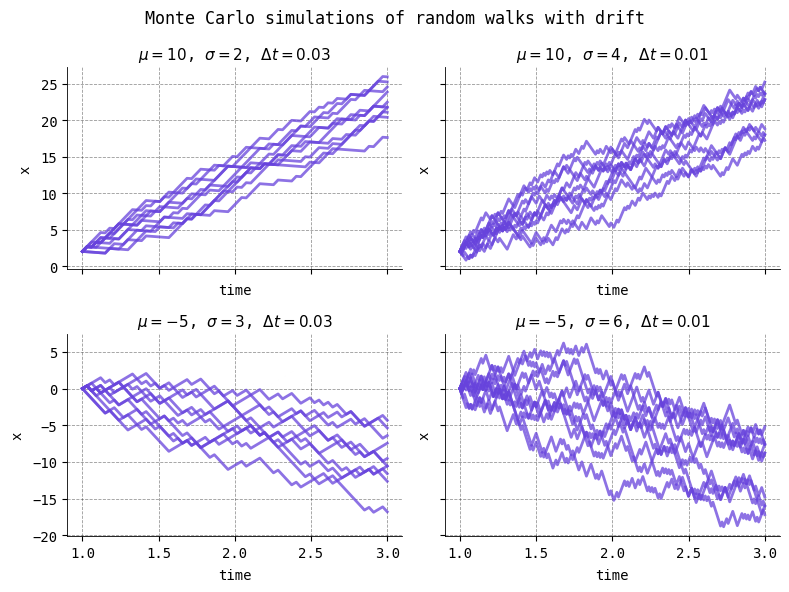

In [2]:
import matplotlib.pyplot as plt
import sigalg as sa

sa.style.use_globally()


def generate_random_walk(mu, sigma, X_a, a, b, Delta_t, n_trajectories, random_state):  # noqa: D103
    T = sa.Time.continuous(start=a, stop=b, dt=Delta_t)
    Z = sa.RandomWalk.generate(
        n_trajectories=n_trajectories, index=T, name="Z", random_state=random_state
    )

    return (
        (mu * Delta_t + sigma * Delta_t ** (1 / 2) * Z.increments(forward=False))
        .cumsum()
        .insert_rv(time=a, state=0)
        + X_a
    ).with_name("X")


params = [
    {"mu": 10, "sigma": 2, "X_a": 2, "Delta_t": 0.03},
    {"mu": 10, "sigma": 4, "X_a": 2, "Delta_t": 0.01},
    {"mu": -5, "sigma": 3, "X_a": 0, "Delta_t": 0.03},
    {"mu": -5, "sigma": 6, "X_a": 0, "Delta_t": 0.01},
]

fig, axs = plt.subplots(2, 2, figsize=(8, 6), sharex=True, sharey="row")

for param, ax in zip(params, axs.flat):
    X = generate_random_walk(**param, a=1, b=3, n_trajectories=10, random_state=42)
    X.plot_trajectories(
        ax=ax,
        y_label="x",
        plot_kwargs={"alpha": 0.75},
        title=rf"$\mu={param['mu']}$, $\sigma={param['sigma']}$, $\Delta t={param['Delta_t']}$",
    )
fig.suptitle("Monte Carlo simulations of random walks with drift")
plt.tight_layout()
plt.show()

## Standard and arithmetic Brownian motions

We return to the net displacement $X_b-X_a$ of our particle given in (2) with chosen drift and diffusion coefficients $\mu$ and $\sigma$:
$$
X_b - X_a = \mu(b-a) + \sigma  \left(\frac{\sum_{k=0}^{n-1} \sqrt{b-a}\, \Delta Z_{t_k}}{\sqrt{n}}\right).
$$
As we let the number $n$ of particle impacts go to $\infty$, the Central Limit Theorem applies to the random variable in parentheses, showing that it converges in distribution to an $\mathcal{N}(0, b-a)$ random variable. Thus, in the limit, the net displacement $X_b- X_a$ is an $\mathcal{N}(\mu(b-a), \sigma^2(b-a))$ random variable.

For large $n$ (i.e., small $\Delta t$) the net displacement is only approximately normal. We plot one such approximation in the next code cell.

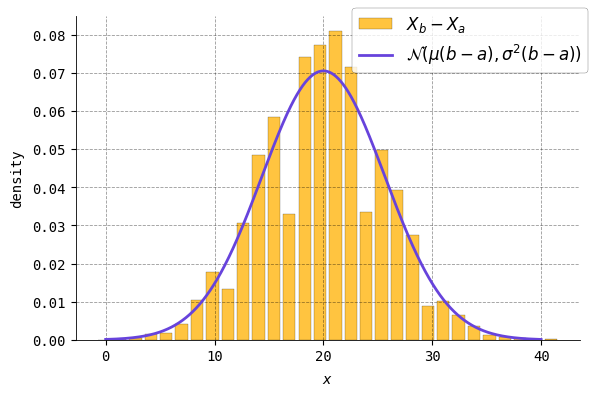

In [3]:
import numpy as np
from scipy.stats import norm

mu, sigma, X_a, a, b, Delta_t = 10, 4, 2, 1, 3, 0.01

X = generate_random_walk(
    mu, sigma, X_a, a, b, Delta_t, n_trajectories=10_000, random_state=42
)

X_b = X.last_rv
x = np.arange(0, 40, step=0.01)
N = norm(loc=mu * (b - a), scale=sigma * np.sqrt(b - a))

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(
    X_b - X_a,
    bins=30,
    color=sa.style.amber,
    density=True,
    edgecolor="black",
    rwidth=0.8,
    alpha=0.75,
    label=r"$X_b-X_a$",
)
ax.plot(x, N.pdf(x), label=r"$\mathcal{N}(\mu(b-a), \sigma^2(b-a))$")
ax.set_xlabel("$x$")
ax.set_ylabel("density")
fig.legend()
plt.tight_layout()
plt.show()

Our disucssion has led us to the following. For a particle undergoing continuous impacts and experiencing *true* Brownian motion, it is natural to model its net displacement $X_{t_2}-X_{t_1}$ over a time interval $[t_1,t_2]$ according to the equation
$$
X_{t_2}-X_{t_1} = \mu(t_2-t_1) + \sigma(W_{t_2} - W_{t_1}),
$$
where $\mu$ and $\sigma>0$ are parameters, and $W_t$ is a continuous-time stochastic process, indexed by $t\in [0,\infty)$, with the following properties:

1. The random variable $W_0$ is deterministic, equal to $0$.
2. For any $0 \leq t_1 < t_2$, the random variable $W_{t_2} - W_{t_1}$ is an $\mathcal{N}(0, t-s)$ random variable.
3. For any $0 \leq t_1 < t_2 < \cdots < t_n$, the random variables $W_{t_2} - W_{t_1}, \ldots, W_{t_n} - W_{t_{n-1}}$ are independent.
4. The trajectories (i.e., sample paths) of the stochastic process are continuous.

A stochastic process $W_t$ with these properties is called a *standard Brownian motion*, while the process $X_t$ is called an *arithmetic Brownian motion* with drift parameter $\mu$ and diffusion parameter $\sigma$.

Whether or not such processes actually *exist* is a difficult matter. While they had appeared before in papers of Thiele (1880), Bachelier (1900) and Einstein (1905), it was Wiener (1923) who first provided a rigorous construction leading to them also being called *Wiener processes*. To see part of the difficulty in proving the existence of a Brownian motion, note that the standard deviation of the random variable $W_{t_2} - W_{t_1}$ is $\sqrt{t_2 - t_1}$. If we use this quantity as a proxy for the net displacement of a particle, then dividing it by $t_2-t_1$ would serve as a measure of the average velocity of the particle over the time interval $[t_1,t_2]$. But this velocity blows up to $\infty$ as $t_2\to t_1$, suggesting that a particle undergoing Brownian motion has *extremely* erratic behavior. This also suggests that the techniques of classical calculus will be inadequate to treat Brownian motion, and that a new *stochastic calculus* will be required.

SigAlg provides a method `BrownianMotion` for simulating standard and arithmetic Brownian motions. To describe it, suppose we partition a time interval $[a,b]$ as
$$
a = t_0 < t_1 < \cdots < t_n = b,
$$
in such a way that the lengths $\Delta t = t_{k+1}-t_k$ are constant for each $k=0,1,\ldots,n-1$. Taking $W_a=0$, we then have
$$
W_{t_k} = \sum_{j=0}^{k-1} (W_{t_{j+1}} - W_{t_j}).
$$
Given the partition of $[a,b]$ above, SigAlg samples from the random variables $W_{t_{j+1}} - W_{t_j} \sim \mathcal{N}(0,\Delta t)$ and sums them to produce a sample from $W_{t_k}$. These samples are then combined into a discrete approximation of the standard Brownian motion. A similar technique is used to simulate arithmetic Brownian motions.

In the next code cell, we plot sampled trajectories of standard and arithmetic Brownian motions, over the time interval $[0,3]$ with $\Delta t=0.01$, and with drift and diffusion coefficients $\mu=1$ and $\sigma=2$. To show the statistical trends of the trajectories, the gray bands plot the regions bounded by $\pm 2 \sqrt{t}$ for the standard motion, and $\mu t \pm 2\sigma \sqrt{t}$ for the arithmetic one. For a given $t$, these are the regions within two standard deviations of the mean.

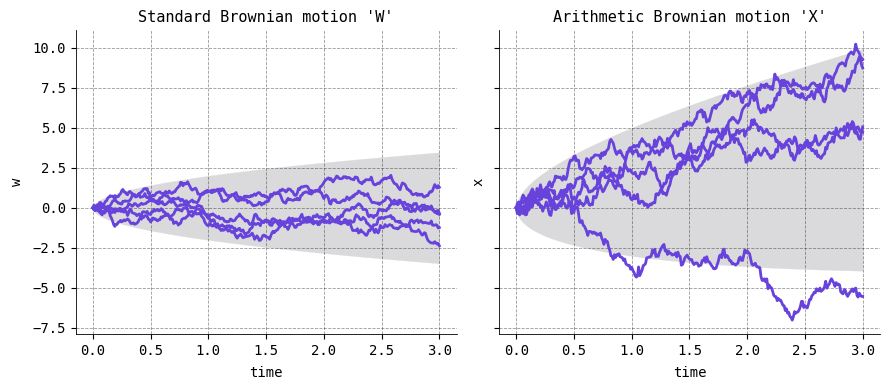

In [4]:
mu, sigma, dt = 1, 2, 0.01
T = sa.Time.continuous(start=0, stop=3, dt=0.01)

W = sa.BrownianMotion.generate(n_trajectories=5, index=T, random_state=42, name="W")
X = sa.BrownianMotion.generate(
    drift=mu, diffusion=sigma, n_trajectories=5, index=T, random_state=24
)

_, axs = plt.subplots(ncols=2, sharey=True, figsize=(9, 4))

W.plot_trajectories(ax=axs[0], y_label="w", title="Standard Brownian motion 'W'")
axs[0].fill_between(T, 2 * np.sqrt(T), -2 * np.sqrt(T), color=sa.style.gray)

X.plot_trajectories(ax=axs[1], y_label="x", title="Arithmetic Brownian motion 'X'")
axs[1].fill_between(
    T,
    mu * T.data + 2 * sigma * np.sqrt(T),
    mu * T.data - 2 * sigma * np.sqrt(T),
    color=sa.style.gray,
)

plt.tight_layout()
plt.show()